### Transformata Hougha w przestrzeni ab - Domowe
Przestrzeń ρ,θ nie jest jedyną przestrzenią w której punkt odpowiada parametrom prostej. Np. można spróbować wykorzystać tradycyjne równanie prostej:

y=ax+b

W tej przestrzeni reprezentacją pęku prostych jest prosta. 

Zadanie: napisać funkcję, która jako argument przyjmuje obraz (binarny) oraz parametry:

- aMin - minimalna wartość parametru a
- aMax - maksymalna  wartość parametru a
- aSkok - skok parametru a
- bMin - minimalna wartość parametru b
- bMax  - maksymalna  wartość parametru b
- bSkok - skok parametru b
Jako wynik ma zwrócić macierz przestrzeni Hougha ab.

Uwagi:

- zadanie może wyglądać na skomplikowane ale tak na prawdę wymaga tylko starannego przemyślenia
- najważniejszy jest problem "adresowania" macierzy H. Można do tego wykorzystać dwa wektory A i B ze wszystkimi możliwymi wartościami jakie parametry a i b mogę przyjąć (w podanych zakresach z podanym skokiem). Wówczas indeksy tych wektorów będą współrzędnymi w macierzy H. Do stworzenia wektorów wykorzystaj funkcję _np.arange_
- na podstawie rozmiaru wektorów A i B (własność _shape_) należy stworzyć wyzerowaną macierz H (funkcja _np.zeros_)
- dla każdego punktu krawędzi na obrazie należy:
    - używająć wektora A dla każdej z jego wartości a obliczyć odpowiednią wartość b - indeksy kolejnych wartości a (a_idx) będą jedną z współrzędnych macierzy H, natomiast drugą współrędną mozna uzyskać jako b_idx = np.argmin(abs(B - b)).
        - każde a_idx i b_idx wyznaczą punkt w macierzy H, który należy zinkrementować
- działanie funkcji należy przetestować na punktach generowanych w 'edytorku' z punktu "Transformacja Hougha dla małej liczby punktów". Proponowane parametry funkcji:
    - aMin: -5
    - aMax:  5
    - aSkok: 0.05 
    - bMin: -100
    - bMax:  100
    - bSkok: 1

Zastanów się w przypadku jakich prostych reprezentacja ab nie sprawdzi się.

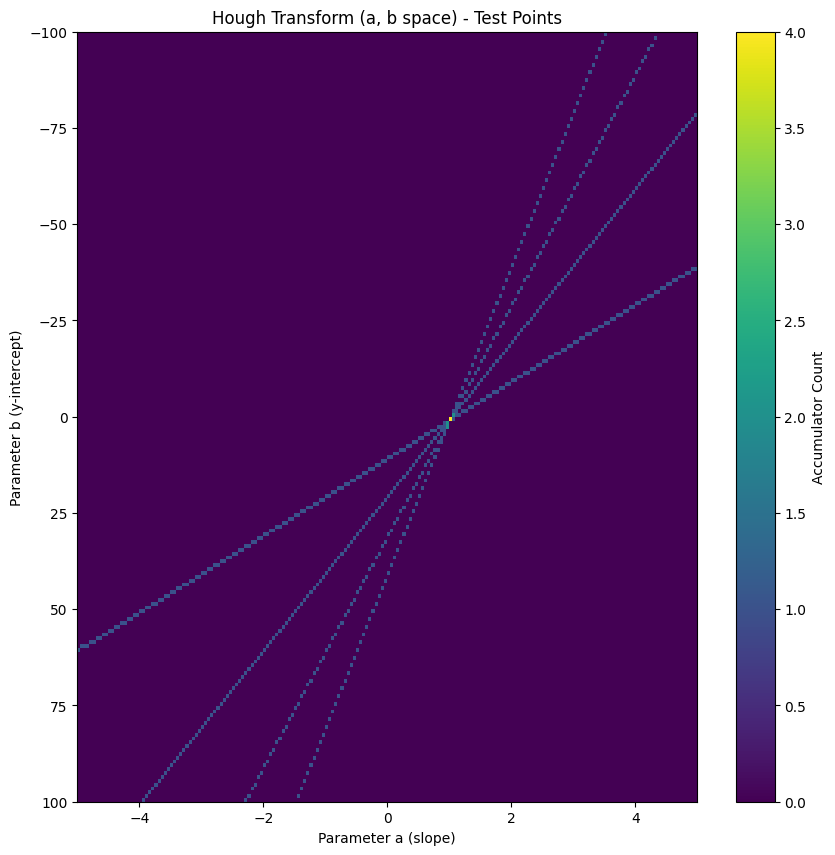

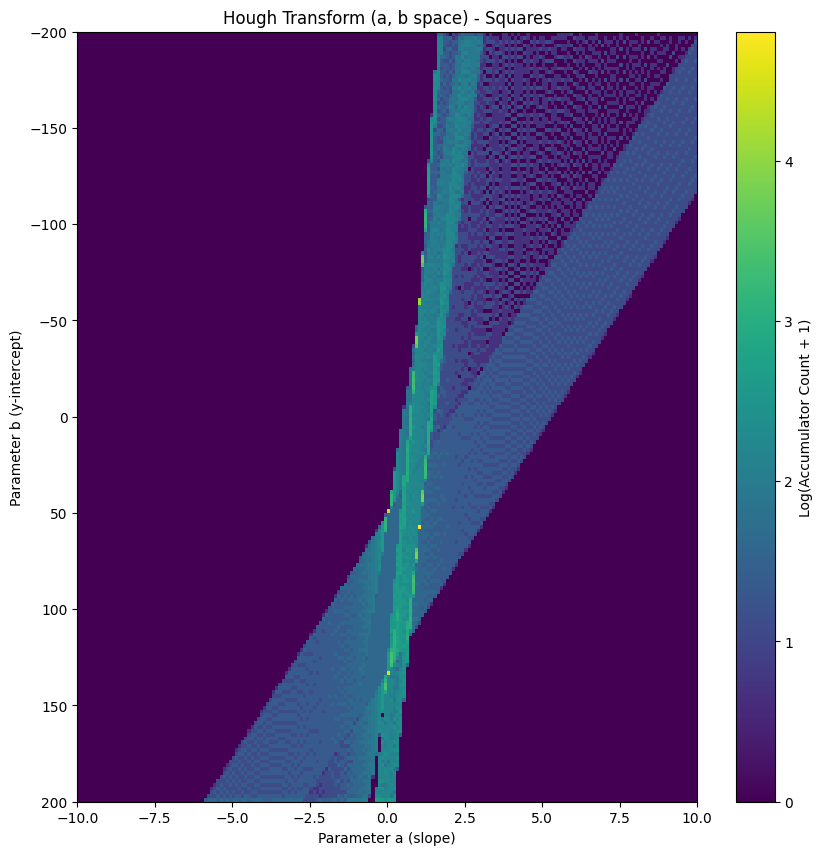

In [2]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from skimage.transform import hough_line, hough_line_peaks
import os
import requests

url = 'https://raw.githubusercontent.com/vision-agh/poc_sw/master/11_Hough/'

fileNames = ["dom.png", "kwadraty.png", "lab112.png"]
for fileName in fileNames:
  if not os.path.exists(fileName):
      r = requests.get(url + fileName, allow_redirects=True)
      open(fileName, 'wb').write(r.content)

def hough_ab_transform(image, a_min, a_max, a_step, b_min, b_max, b_step):
    A = np.arange(a_min, a_max, a_step)
    B = np.arange(b_min, b_max, b_step)
    
    H = np.zeros((B.shape[0], A.shape[0]), dtype=np.uint64)
    ys, xs = np.nonzero(image)

    for y, x in zip(ys, xs):
        for a_idx, a in enumerate(A):
            b = y - a * x
            
            if b >= b_min and b < b_max:
                b_idx = np.argmin(np.abs(B - b))
                H[b_idx, a_idx] += 1
                
    return H, A, B

test_image = np.zeros((64, 64), dtype=np.uint8)

test_image[10, 10] = 1 
test_image[20, 20] = 1
test_image[30, 30] = 1
test_image[40, 40] = 1

a_min_param = -5
a_max_param = 5
a_step_param = 0.05
b_min_param = -100
b_max_param = 100
b_step_param = 1

H_ab_result, A_vector, B_vector = hough_ab_transform(
    test_image, a_min_param, a_max_param, a_step_param, b_min_param, b_max_param, b_step_param
)

plt.figure(figsize=(10, 10))
plt.imshow(H_ab_result, aspect='auto', extent=[a_min_param, a_max_param, b_max_param, b_min_param])
plt.title('Hough Transform (a, b space) - Test Points')
plt.xlabel('Parameter a (slope)')
plt.ylabel('Parameter b (y-intercept)')
plt.colorbar(label='Accumulator Count')
plt.show()

squares_image_gray = cv2.imread('kwadraty.png', cv2.IMREAD_GRAYSCALE)
squares_edges = cv2.Canny(squares_image_gray, 50, 150, apertureSize=3)

H_ab_squares, A_vec_sq, B_vec_sq = hough_ab_transform(
    squares_edges, -10, 10, 0.1, -200, 200, 2 
)

plt.figure(figsize=(10, 10))
plt.imshow(np.log1p(H_ab_squares), aspect='auto', extent=[-10, 10, 200, -200]) 
plt.title('Hough Transform (a, b space) - Squares')
plt.xlabel('Parameter a (slope)')
plt.ylabel('Parameter b (y-intercept)')
plt.colorbar(label='Log(Accumulator Count + 1)')
plt.show()